# Fig5 main panels c-m

This notebook redraws panels c through m only. It uses the minimal reproducible data bundle under `OmicOS_reproduce/data` and does not create a combined total figure.

## Setup

In [1]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import display, Image as IPyImage

ROOT = Path(".").resolve()
DATA = ROOT / "data"
OUT = ROOT / "outputs"
PANEL = OUT / "panels"
for d in [OUT, PANEL]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "Liberation Sans"],
    "font.size": 18,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "axes.linewidth": 0.7,
    "axes.titlepad": 3.0,
    "lines.linewidth": 1.2,
    "patch.linewidth": 0.7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

MARKER_GROUPS = [
    "epithelial_tumor", "stromal_ecm", "immune", "vascular",
    "proliferation", "hypoxia_stress",
]

DOMAIN_COLORS = [
    "#1f77b4", "#ffbf00", "#2ca02c", "#d62728", "#9467bd", "#17becf",
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#003f5c", "#ffa600",
    "#4daf4a", "#984ea3", "#f781bf", "#a65628", "#999999", "#66c2a5",
]
DOMAIN_COLOR_MAP_12 = {
    "0": "#8D1E54",
    "1": "#D1669D",
    "2": "#D9A3C2",
    "3": "#E37874",
    "4": "#215677",
    "5": "#2B90C7",
    "6": "#F0EDEF",
    "7": "#30824F",
    "8": "#7AB35E",
    "9": "#5A4B92",
    "10": "#E7EAC2",
    "11": "#F1B622",
}
ST_DOMAIN_PALETTE = {
    "0": "#8D1E54",
    "1": "#D98DB8",
    "2": "#D8C5CF",
    "3": "#E07A6A",
    "4": "#2C5D86",
    "5": "#4BA3D9",
    "6": "#E7EAC2",
    "7": "#49A05A",
}

def read_csv(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)

def natural_key(value):
    text = str(value).replace("D", "")
    try:
        return (0, float(text.replace("um", "")))
    except ValueError:
        return (1, text)

def panel_label(ax, label):
    label = str(label).lower()
    ax._panel_label = label
    ax.text(-0.065, 1.03, label, transform=ax.transAxes, fontsize=18, fontweight="bold", va="bottom", ha="left")

def clean_axis(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_facecolor("white")

def display_saved_png(path, width=None):
    if width is None:
        display(IPyImage(filename=str(path)))
    else:
        display(IPyImage(filename=str(path), width=width))

def domain_display_label(value):
    text = str(value)
    return text if text.startswith("D") else f"D{text}"

def save_panel(fig, label, name):
    png = PANEL / f"{label}_{name}.png"
    pdf = PANEL / f"{label}_{name}.pdf"
    fig.savefig(png, bbox_inches="tight", pad_inches=0.03)
    fig.savefig(pdf, bbox_inches="tight", pad_inches=0.03)
    print(f"saved panel: {png}")
    print(f"saved panel: {pdf}")
    plt.close(fig)
    display_saved_png(png)

def robust_norm(values):
    values = pd.Series(values).astype(float)
    lo, hi = values.quantile([0.02, 0.98])
    if hi <= lo:
        hi = values.max() if values.max() > lo else lo + 1.0
    return ((values - lo) / (hi - lo)).clip(0, 1)

def row_zscore(frame):
    arr = frame.to_numpy(dtype=float)
    mu = np.nanmean(arr, axis=1, keepdims=True)
    sd = np.nanstd(arr, axis=1, keepdims=True)
    sd[sd == 0] = 1
    return pd.DataFrame((arr - mu) / sd, index=frame.index, columns=frame.columns)

def validate_columns(frame, columns, name):
    missing = sorted(set(columns).difference(frame.columns))
    if missing:
        raise ValueError(f"{name} is missing required columns: {missing}")

In [2]:
def draw_he_footprint(ax, tiles):
    info = json.loads((DATA / "visium_hd_he_page_info.json").read_text())
    thumb = np.load(DATA / "visium_hd_he_thumbnail_stride32.npy")
    ax.imshow(thumb, extent=(0, info["width"], info["height"], 0))
    sample = tiles.iloc[::20]
    ax.scatter(sample["center_x"], sample["center_y"], s=1.0, c="#00a6d6", alpha=0.35, linewidths=0, rasterized=True)
    x0, x1 = tiles["center_x"].min(), tiles["center_x"].max()
    y0, y1 = tiles["center_y"].min(), tiles["center_y"].max()
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#000000", linewidth=1.2))
    ax.set_title("H&E overview", fontsize=18)
    clean_axis(ax)

def categorical_spatial(
    ax,
    df,
    column,
    title,
    x="center_x",
    y="center_y",
    size=4.0,
    palette=None,
    legend=True,
    fontsize=18,
    draw_border=True,
    border_pad_frac=0.006,
    legend_reserved_frac=0.24,
):
    vals = df[column].astype(str)
    cats = sorted(vals.dropna().unique(), key=natural_key)
    if palette is None:
        color_map = {cat: DOMAIN_COLORS[i % len(DOMAIN_COLORS)] for i, cat in enumerate(cats)}
    else:
        color_map = {cat: palette.get(cat, "#999999") for cat in cats}
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()
    dx = x1 - x0
    dy = y1 - y0
    pad_x = dx * border_pad_frac
    pad_y = dy * border_pad_frac
    legend_space = dx * legend_reserved_frac if legend and len(cats) <= 12 else 0.0
    ax.scatter(df[x], df[y], c=vals.map(color_map).fillna("#cccccc"), s=size, linewidths=0, rasterized=True)
    if draw_border:
        ax.add_patch(Rectangle((x0, y0), dx, dy, fill=False, edgecolor="black", linewidth=1.2, zorder=10, clip_on=False))
    ax.set_xlim(x0 - pad_x, x1 + pad_x + legend_space)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, fontsize=fontsize, pad=8)
    clean_axis(ax)
    if legend and len(cats) <= 12:
        handles = [
            Line2D([0], [0], marker="o", color="none", markerfacecolor=color_map[c], markeredgecolor="black", markeredgewidth=1.2, markersize=15, label=domain_display_label(c))
            for c in cats
        ]
        ax.legend(handles=handles, loc="center left", bbox_to_anchor=(0.82, 0.5), bbox_transform=ax.transAxes, frameon=False, ncol=2, fontsize=fontsize, handletextpad=0.35, columnspacing=0.85, labelspacing=0.40, borderaxespad=0.0)

def categorical_umap(
    ax,
    df,
    column,
    title,
    x="umap1",
    y="umap2",
    size=2.0,
    alpha=0.65,
    palette=None,
    legend=True,
    fontsize=18,
    legend_reserved_frac=0.32,
    arrow_origin=(0.08, 0.10),
    arrow_len=0.16,
):
    vals = df[column].astype(str)
    cats = sorted(vals.dropna().unique(), key=natural_key)
    if palette is None:
        color_map = {cat: DOMAIN_COLORS[i % len(DOMAIN_COLORS)] for i, cat in enumerate(cats)}
    else:
        color_map = {cat: palette.get(cat, "#999999") for cat in cats}
    ax.scatter(df[x], df[y], c=vals.map(color_map).fillna("#cccccc"), s=size, alpha=alpha, linewidths=0, rasterized=True)
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()
    dx = x1 - x0
    dy = y1 - y0
    pad_x = dx * 0.04
    pad_y = dy * 0.04
    legend_space = dx * legend_reserved_frac if legend and len(cats) <= 12 else 0
    ax.set_xlim(x0 - pad_x, x1 + pad_x + legend_space)
    ax.set_ylim(y0 - pad_y, y1 + pad_y)
    clean_axis(ax)
    ax.set_title(title, fontsize=fontsize, pad=6)
    ox, oy = arrow_origin
    ax.annotate("", xy=(ox + arrow_len, oy), xytext=(ox, oy), xycoords="axes fraction", textcoords="axes fraction", arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black", shrinkA=0, shrinkB=0, mutation_scale=14), clip_on=False)
    ax.annotate("", xy=(ox, oy + arrow_len), xytext=(ox, oy), xycoords="axes fraction", textcoords="axes fraction", arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black", shrinkA=0, shrinkB=0, mutation_scale=14), clip_on=False)
    ax.text(ox + arrow_len * 0.55, oy - 0.025, "UMAP1", transform=ax.transAxes, fontsize=fontsize, ha="center", va="top")
    ax.text(ox - 0.015, oy + arrow_len * 0.55, "UMAP2", transform=ax.transAxes, fontsize=fontsize, ha="right", va="center", rotation=90)
    if legend and len(cats) <= 12:
        handles = [
            Line2D([0], [0], marker="o", color="none", markerfacecolor=color_map[c], markeredgecolor="none", markersize=9, label=c)
            for c in cats
        ]
        ax.legend(handles=handles, loc="center left", bbox_to_anchor=(0.80, 0.52), bbox_transform=ax.transAxes, frameon=False, fontsize=fontsize, ncol=1, handletextpad=0.45, labelspacing=0.35, borderaxespad=0.0)
    return ax

def continuous_spatial(
    ax,
    df,
    column,
    title,
    x="center_x",
    y="center_y",
    cmap="magma",
    size=1.5,
    fontsize=18,
    vmin=None,
    vmax=None,
    quantile_clip=(0.02, 0.98),
    draw_border=True,
    border_pad_frac=0.006,
    border_linewidth=1.2,
):
    vals = df[column].astype(float)
    if vmin is None or vmax is None:
        q1, q2 = vals.quantile(list(quantile_clip)).tolist()
        if vmin is None:
            vmin = q1
        if vmax is None:
            vmax = q2
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()
    dx = x1 - x0
    dy = y1 - y0
    pad_x = dx * border_pad_frac
    pad_y = dy * border_pad_frac
    im = ax.scatter(df[x], df[y], c=vals, s=size, linewidths=0, cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True)
    ax.set_xlim(x0 - pad_x, x1 + pad_x)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, fontsize=fontsize, pad=8)
    clean_axis(ax)
    if draw_border:
        ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, edgecolor="black", linewidth=border_linewidth, zorder=10, clip_on=False))
    return im

def add_shared_colorbar(fig, cmap="magma", vmin=0.0, vmax=1.0, label="Marker score", fontsize=18, cax_position=(0.92, 0.18, 0.018, 0.64)):
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cax = fig.add_axes(cax_position)
    cax._skip_panel = True
    cb = fig.colorbar(sm, cax=cax)
    cb.ax.tick_params(labelsize=fontsize, length=3, width=1.0, pad=4)
    if label:
        cb.set_label(label, fontsize=fontsize, labelpad=10)
    cb.outline.set_linewidth(1.0)
    return cb

def draw_representative_tiles(fig, subspec, rows, n=6, fontsize=15, title_pad=8, wspace=-0.1, hspace=0.24, border=True, border_linewidth=1.2):
    gs = subspec.subgridspec(2, 3, wspace=wspace, hspace=hspace)
    axes = []
    for i, (_, row) in enumerate(rows.head(n).iterrows()):
        ax = fig.add_subplot(gs[i // 3, i % 3])
        crop = Image.open(DATA / "representative_tiles" / row["crop_file"])
        ax.imshow(crop)
        ax.set_title(f"D{row['smoothed_domain']} | {row['marker_proxy_group']}", fontsize=fontsize, pad=title_pad)
        clean_axis(ax)
        if border:
            ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, edgecolor="black", linewidth=border_linewidth, zorder=10, clip_on=False))
        axes.append(ax)
    panel_label(axes[0], "e")
    return axes

def spatial_binary(ax, df, column, title, true_color="#d62728", false_color="#cfcfcf", size=4.0):
    values = df[column].astype(bool)
    colors = np.where(values, true_color, false_color)
    x0, x1 = df["center_x"].min(), df["center_x"].max()
    y0, y1 = df["center_y"].min(), df["center_y"].max()
    dx = x1 - x0
    dy = y1 - y0
    pad_x = dx * 0.006
    pad_y = dy * 0.006
    ax.scatter(df["center_x"], df["center_y"], c=colors, s=size, linewidths=0, rasterized=True)
    ax.set_xlim(x0 - pad_x, x1 + pad_x)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)
    ax.set_aspect("equal", adjustable="box")
    clean_axis(ax)
    ax.add_patch(Rectangle((x0, y0), dx, dy, fill=False, edgecolor="black", linewidth=1.2, zorder=10, clip_on=False))
    ax.set_title(title, fontsize=18)
    ax.legend(
        handles=[
            Line2D([0], [0], marker="o", color="none", markerfacecolor=true_color, markeredgecolor="black", markersize=12, label="Cancer-enriched tiles"),
            Line2D([0], [0], marker="o", color="none", markerfacecolor=false_color, markeredgecolor="black", markersize=12, label="Other tiles"),
        ],
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        borderaxespad=0.0,
        handlelength=1.0,
        handletextpad=0.15,
        labelspacing=0.35,
        fontsize=18,
    )

def spatial_tumor_immune_on_he(
    ax,
    df,
    title="Predicted ST tumor and immune programs",
    x="center_x",
    y="center_y",
    quantile_threshold=0.65,
    size=5.0,
    alpha=0.70,
    he_alpha=0.55,
    fontsize=18,
    draw_border=True,
    border_pad_frac=0.006,
    legend_space_frac=0.28,
):
    info = json.loads((DATA / "visium_hd_he_page_info.json").read_text())
    thumb = np.load(DATA / "visium_hd_he_thumbnail_stride32.npy")
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()
    dx = x1 - x0
    dy = y1 - y0
    pad_x = dx * border_pad_frac
    pad_y = dy * border_pad_frac
    ax.imshow(thumb, extent=(0, info["width"], info["height"], 0), alpha=he_alpha, zorder=0)
    tumor = robust_norm(df["epithelial_tumor"])
    immune = robust_norm(df["immune"])
    keep_tumor = tumor >= tumor.quantile(quantile_threshold)
    keep_immune = immune >= immune.quantile(quantile_threshold)
    sc_immune = ax.scatter(df.loc[keep_immune, x], df.loc[keep_immune, y], c=immune.loc[keep_immune], cmap="Blues", vmin=0, vmax=1, s=size, alpha=alpha, linewidths=0, rasterized=True, zorder=2)
    sc_tumor = ax.scatter(df.loc[keep_tumor, x], df.loc[keep_tumor, y], c=tumor.loc[keep_tumor], cmap="Reds", vmin=0, vmax=1, s=size, alpha=alpha, linewidths=0, rasterized=True, zorder=3)
    if draw_border:
        ax.add_patch(Rectangle((x0, y0), dx, dy, fill=False, edgecolor="black", linewidth=1.2, zorder=10, clip_on=False))
    ax.set_xlim(x0 - pad_x, x1 + pad_x + dx * legend_space_frac)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, fontsize=fontsize, pad=8)
    clean_axis(ax)
    return sc_tumor, sc_immune

def add_tumor_immune_colorbars(fig, sc_tumor, sc_immune, x0=0.79, y0=0.62, width=0.12, height=0.025, y_gap=0.16, fontsize=14):
    items = [("Tumor signature", "#d62728", sc_tumor), ("Immune signature", "#2C7FB8", sc_immune)]
    for i, (title, color, sc) in enumerate(items):
        cax = fig.add_axes([x0, y0 - i * y_gap, width, height])
        cax._skip_panel = True
        cb = fig.colorbar(sc, cax=cax, orientation="horizontal")
        cb.ax.tick_params(labelsize=fontsize * 0.80, length=3, width=1.0, pad=1)
        cb.set_ticks([0, 0.5, 1.0])
        cb.set_ticklabels(["0", "0.5", "1"])
        cax.set_title(title, fontsize=fontsize, color=color, pad=8)
        for spine in cax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.0)
            spine.set_edgecolor("black")

In [3]:
SAMPLE_COLORS = {
    "TCGA-55-8620": "#b2182b",
    "TCGA-55-A490": "#ef8a62",
    "TCGA-62-A46S": "#2166ac",
    "TCGA-78-7537": "#67a9cf",
}
REGION_FEATURE_COLORS = {
    "Mixed C5: high-risk enriched": "#d73027",
    "Shared C6: low-risk enriched": "#4575b4",
    "Other regions": "#d0d0d0",
}
C5_C6_REGION_FEATURES = [
    ("Mixed C5", "Mixed C5: high-risk enriched"),
    ("Shared C6", "Shared C6: low-risk enriched"),
]
C5_C6_STACKED_BARPLOT_LABELS = {}
SIGNAL_COLUMNS = [
    "tissue_fraction",
    "mean_hematoxylin",
    "mean_eosin",
    "mean_saturation",
    "mean_value",
    "mean_edge_density",
    "std_gray",
    "tumor_proxy_score",
    "immune_proxy_score",
    "stromal_proxy_score",
    "necrosis_proxy_score",
]
BIOLOGICAL_PROGRAMS = {
    "Necrosis/hypoxia-like pale": [
        ("necrosis_proxy_score", 1.0),
        ("mean_value", 1.0),
        ("mean_saturation", -1.0),
        ("tissue_fraction", -1.0),
        ("mean_hematoxylin", -1.0),
    ],
    "Viable tumor-epithelial cellular": [
        ("tumor_proxy_score", 1.0),
        ("mean_hematoxylin", 1.0),
        ("mean_edge_density", 1.0),
        ("std_gray", 1.0),
        ("necrosis_proxy_score", -1.0),
        ("mean_value", -1.0),
    ],
    "Immune-inflamed cellular": [
        ("immune_proxy_score", 1.0),
        ("mean_hematoxylin", 1.0),
        ("mean_edge_density", 1.0),
        ("std_gray", 1.0),
    ],
    "Stromal/ECM fibrotic": [
        ("stromal_proxy_score", 1.0),
        ("mean_eosin", 1.0),
        ("mean_saturation", 1.0),
        ("tumor_proxy_score", -0.5),
        ("immune_proxy_score", -0.5),
    ],
    "Low-cellularity pale tissue": [
        ("mean_value", 1.0),
        ("tissue_fraction", -1.0),
        ("mean_hematoxylin", -1.0),
        ("mean_edge_density", -1.0),
        ("std_gray", -1.0),
    ],
    "Nuclear texture/proliferation proxy": [
        ("mean_hematoxylin", 1.0),
        ("mean_edge_density", 1.0),
        ("std_gray", 1.0),
    ],
}

def assign_key_region_feature(region_label):
    if region_label == "Mixed C5":
        return "Mixed C5: high-risk enriched"
    if region_label == "Shared C6":
        return "Shared C6: low-risk enriched"
    return "Other regions"

def patient_order(tile_df):
    risk_rank = {"High risk": 0, "Low risk": 1}
    meta = tile_df[["patient_id", "risk_group"]].drop_duplicates()
    meta["risk_rank"] = meta["risk_group"].map(risk_rank).fillna(99)
    return meta.sort_values(["risk_rank", "patient_id"])["patient_id"].tolist()

def draw_umap_arrow_axes(ax, fontsize=18):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    for spine in ax.spines.values():
        spine.set_visible(False)
    x0, y0 = 0.18, 0.12
    x1, y1 = 0.34, 0.28
    arrow_style = dict(arrowstyle="-|>", lw=4.0, color="black", mutation_scale=22, shrinkA=0, shrinkB=0)
    ax.annotate("", xy=(x1, y0), xytext=(x0, y0), xycoords="axes fraction", arrowprops=arrow_style, zorder=30, clip_on=False)
    ax.annotate("", xy=(x0, y1), xytext=(x0, y0), xycoords="axes fraction", arrowprops=arrow_style, zorder=30, clip_on=False)
    ax.text((x0 + x1) / 2, y0 - 0.08, "UMAP1", transform=ax.transAxes, ha="center", va="top", fontsize=fontsize, zorder=31, clip_on=False)
    ax.text(x0 - 0.075, (y0 + y1) / 2, "UMAP2", transform=ax.transAxes, ha="center", va="center", rotation=90, fontsize=fontsize, zorder=31, clip_on=True)

def plot_umap_sample_vs_regions(tile_df, path_base):
    tile_df = tile_df.copy()
    tile_df["region_feature"] = tile_df["region_label"].map(assign_key_region_feature)
    patients = patient_order(tile_df)
    fig, axes = plt.subplots(2, 1, figsize=(4, 8), sharex=True, sharey=True)
    x_min, x_max = tile_df["umap_1"].min(), tile_df["umap_1"].max()
    y_min, y_max = tile_df["umap_2"].min(), tile_df["umap_2"].max()
    x_pad = 0.05 * (x_max - x_min)
    y_pad = 0.05 * (y_max - y_min)
    ax = axes[0]
    sample_handles = []
    for patient in patients:
        sub = tile_df.loc[tile_df["patient_id"].eq(patient)]
        risk = sub["risk_group"].iloc[0]
        color = SAMPLE_COLORS.get(patient, "#666666")
        ax.scatter(sub["umap_1"], sub["umap_2"], s=8, c=color, alpha=0.65, linewidths=0, rasterized=True)
        sample_handles.append(Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=color, markeredgecolor="black", markersize=7, label=f"{patient} ({risk})"))
    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)
    ax.grid(False)
    draw_umap_arrow_axes(ax, fontsize=18)
    leg1 = ax.legend(handles=sample_handles, frameon=False, loc="upper left", bbox_to_anchor=(1.03, 1.00), borderaxespad=0.0, handlelength=1.0, handletextpad=0.4, labelspacing=0.45, fontsize=18)
    ax = axes[1]
    for feature in ["Other regions", "Mixed C5: high-risk enriched", "Shared C6: low-risk enriched"]:
        sub = tile_df.loc[tile_df["region_feature"].eq(feature)]
        ax.scatter(sub["umap_1"], sub["umap_2"], s=6 if feature == "Other regions" else 10, c=REGION_FEATURE_COLORS[feature], alpha=0.16 if feature == "Other regions" else 0.82, linewidths=0, rasterized=True)
    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)
    ax.grid(False)
    draw_umap_arrow_axes(ax, fontsize=18)
    feature_handles = [
        Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=REGION_FEATURE_COLORS["Mixed C5: high-risk enriched"], markeredgecolor="black", markersize=7, label="High-risk enriched regions"),
        Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=REGION_FEATURE_COLORS["Shared C6: low-risk enriched"], markeredgecolor="black", markersize=7, label="Low-risk enriched regions"),
        Line2D([0], [0], marker="o", linestyle="none", markerfacecolor=REGION_FEATURE_COLORS["Other regions"], markeredgecolor="black", markersize=7, label="Other regions"),
    ]
    leg2 = ax.legend(handles=feature_handles, frameon=False, loc="upper left", bbox_to_anchor=(1.03, 1.00), borderaxespad=0.0, handlelength=1.0, handletextpad=0.4, labelspacing=0.45, fontsize=18)
    fig.subplots_adjust(left=0.08, right=0.98, top=0.98, bottom=0.06, hspace=0.22)
    fig.savefig(path_base.with_suffix(".png"), dpi=300, bbox_inches="tight", bbox_extra_artists=[leg1, leg2], pad_inches=0.03)
    fig.savefig(path_base.with_suffix(".pdf"), bbox_inches="tight", bbox_extra_artists=[leg1, leg2], pad_inches=0.03)
    plt.close(fig)
    display_saved_png(path_base.with_suffix(".png"), width=900)

def plot_spatial_key_regions(tile_df, path_base):
    tile_df = tile_df.copy()
    tile_df["region_feature"] = tile_df["region_label"].map(assign_key_region_feature)
    patients = patient_order(tile_df)
    fig, axes = plt.subplots(2, 2, figsize=(7.8, 7.2), constrained_layout=True)
    axes = np.ravel(axes).tolist()
    for ax, patient in zip(axes, patients, strict=True):
        sub = tile_df.loc[tile_df["patient_id"].eq(patient)]
        rgb = np.asarray(Image.open(DATA / "luad_matched_slide_thumbnails" / f"{patient}.png"))
        ax.imshow(rgb)
        other = sub.loc[sub["region_feature"].eq("Other regions")]
        ax.scatter(other["tile_center_x"], other["tile_center_y"], s=5, c="#bdbdbd", alpha=0.16, linewidths=0, rasterized=True)
        for feature in ["Mixed C5: high-risk enriched", "Shared C6: low-risk enriched"]:
            focus = sub.loc[sub["region_feature"].eq(feature)]
            ax.scatter(focus["tile_center_x"], focus["tile_center_y"], s=22, c=REGION_FEATURE_COLORS[feature], alpha=0.88, linewidths=0, rasterized=True)
        risk = sub["risk_group"].iloc[0]
        ax.set_title(f"{patient}\n{risk}")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.savefig(path_base.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(path_base.with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)
    display_saved_png(path_base.with_suffix(".png"))

def safe_std(values):
    value = float(np.nanstd(np.asarray(values, dtype=float), ddof=1))
    return value if np.isfinite(value) and value > 0 else 1.0

def zscore_frame(df, columns):
    z = pd.DataFrame(index=df.index)
    for col in columns:
        z[col] = (df[col].astype(float) - float(df[col].mean())) / safe_std(df[col])
    return z.replace([np.inf, -np.inf], np.nan).fillna(0.0)

def compute_biological_program_scores(tile_df):
    missing = sorted(set(SIGNAL_COLUMNS).difference(tile_df.columns))
    if missing:
        raise ValueError(f"tile table missing signal columns: {missing}")
    out = tile_df.copy()
    z = zscore_frame(out, SIGNAL_COLUMNS)
    for program, terms in BIOLOGICAL_PROGRAMS.items():
        weighted = np.zeros(len(out), dtype=float)
        total_weight = 0.0
        for col, weight in terms:
            weighted += float(weight) * z[col].to_numpy(dtype=float)
            total_weight += abs(float(weight))
        out[program] = weighted / max(total_weight, 1.0)
    return out

def compute_c5_c6_program_enrichment(tile_df):
    scored = compute_biological_program_scores(tile_df)
    rows = []
    for region_label, region_feature in C5_C6_REGION_FEATURES:
        region = scored.loc[scored["region_label"].eq(region_label)]
        rest = scored.loc[~scored["region_label"].eq(region_label)]
        if region.empty:
            raise ValueError(f"region not found in tile table: {region_label}")
        for program in BIOLOGICAL_PROGRAMS:
            pooled = math.sqrt((np.nanvar(region[program], ddof=1) + np.nanvar(rest[program], ddof=1)) / 2)
            effect = float((region[program].mean() - rest[program].mean()) / pooled) if np.isfinite(pooled) and pooled > 0 else 0.0
            rows.append({
                "region_label": region_label,
                "region_feature": region_feature,
                "program": program,
                "program_mean": float(region[program].mean()),
                "background_mean": float(rest[program].mean()),
                "cohens_d_vs_other_regions": effect,
            })
    return pd.DataFrame(rows)

def c5_c6_shared_program_order(enrichment):
    c5 = enrichment.loc[enrichment["region_label"].eq("Mixed C5")]
    if c5.empty:
        raise ValueError("Mixed C5 is required to define the shared program order")
    return c5.sort_values("cohens_d_vs_other_regions", ascending=False)["program"].tolist()

def plot_c5_c6_program_enrichment_stacked(tile_df, path_base):
    enrichment = compute_c5_c6_program_enrichment(tile_df)
    programs = c5_c6_shared_program_order(enrichment)
    max_abs = float(np.nanmax(np.abs(enrichment["cohens_d_vs_other_regions"])))
    xlim = max(0.5, math.ceil((max_abs + 0.15) * 10) / 10)
    fig, axes = plt.subplots(2, 1, figsize=(9.6, 7), sharex=True)
    for ax, (region_label, region_feature) in zip(axes, C5_C6_REGION_FEATURES, strict=True):
        sub = enrichment.loc[enrichment["region_label"].eq(region_label)].set_index("program").loc[programs].reset_index()
        region_color = REGION_FEATURE_COLORS[region_feature]
        colors = [region_color if value > 0 else "#bdbdbd" for value in sub["cohens_d_vs_other_regions"]]
        y = np.arange(len(programs))
        ax.barh(y, sub["cohens_d_vs_other_regions"], color=colors, height=0.72)
        ax.set_yticks(y)
        ax.set_yticklabels([C5_C6_STACKED_BARPLOT_LABELS.get(program, program) for program in programs])
        ax.invert_yaxis()
        ax.axvline(0, color="black", linewidth=2.0)
        ax.set_xlim(-xlim, xlim)
        ax.set_title(region_feature, loc="left", fontsize=15)
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        for spine in ["left", "bottom"]:
            ax.spines[spine].set_visible(True)
            ax.spines[spine].set_linewidth(2.0)
        ax.tick_params(axis="both", labelsize=15, width=2.0, length=6)
    axes[-1].set_xlabel("Cohen's d vs other regions", fontsize=15)
    fig.subplots_adjust(left=0.44, right=0.98, top=0.96, bottom=0.08, hspace=0.32)
    fig.savefig(path_base.with_suffix(".png"), dpi=300)
    fig.savefig(path_base.with_suffix(".pdf"))
    plt.close(fig)
    display_saved_png(path_base.with_suffix(".png"))
    return enrichment

In [4]:
def format_pvalue(value):
    return f"{value:.2e}" if value < 0.001 else f"{value:.3f}"

def counts_at_risk(kmf, times):
    event_table = kmf.event_table.assign(at_risk_end=lambda x: x["at_risk"] - x["removed"])
    counts = []
    for time in times:
        rows = event_table.loc[event_table.index <= time]
        if rows.empty:
            counts.append(int(event_table["at_risk"].iloc[0]))
        elif time == 0:
            counts.append(int(rows["at_risk"].iloc[-1]))
        else:
            counts.append(int(rows["at_risk_end"].iloc[-1]))
    return counts

def plot_km_styled(df, path_base):
    from lifelines import CoxPHFitter, KaplanMeierFitter
    from lifelines.statistics import logrank_test

    mpl.rcParams.update({
        "font.size": 18,
        "axes.titlesize": 18,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "axes.grid": False,
        "figure.dpi": 180,
        "savefig.dpi": 320,
    })
    required = {"survival_days", "event", "he_stromal_immune_group"}
    missing = sorted(required - set(df.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["survival_days", "event", "he_stromal_immune_group"]).copy()
    df["survival_days"] = pd.to_numeric(df["survival_days"], errors="coerce")
    df["event"] = pd.to_numeric(df["event"], errors="coerce")
    df = df[(df["survival_days"] > 0) & df["event"].isin([0, 1])].copy()
    high_label = "HE stromal-immune high"
    low_label = "HE stromal-immune low"
    plot_order = [high_label, low_label]
    missing_groups = [g for g in plot_order if g not in set(df["he_stromal_immune_group"])]
    if missing_groups:
        raise ValueError(f"Missing expected groups: {missing_groups}")
    high = df[df["he_stromal_immune_group"] == high_label]
    low = df[df["he_stromal_immune_group"] == low_label]
    logrank = logrank_test(high["survival_days"], low["survival_days"], high["event"], low["event"])
    cox_df = df[["survival_days", "event", "he_stromal_immune_group"]].copy()
    cox_df["he_stromal_immune_high"] = (cox_df["he_stromal_immune_group"] == high_label).astype(float)
    cph = CoxPHFitter(penalizer=0.05)
    cph.fit(cox_df[["survival_days", "event", "he_stromal_immune_high"]], duration_col="survival_days", event_col="event")
    cox_row = cph.summary.loc["he_stromal_immune_high"]
    hr = float(cox_row["exp(coef)"])
    fig = plt.figure(figsize=(5.0, 6.0), constrained_layout=False)
    gs = fig.add_gridspec(nrows=2, ncols=1, height_ratios=[4.6, 1.0], hspace=0.30)
    ax = fig.add_subplot(gs[0])
    ax_risk = fig.add_subplot(gs[1], sharex=ax)
    colors = {high_label: "#1B9E77", low_label: "#D95F02"}
    display_labels = {high_label: "High", low_label: "Low"}
    fitters = {}
    for label in plot_order:
        group = df[df["he_stromal_immune_group"] == label]
        kmf = KaplanMeierFitter(label=display_labels[label])
        kmf.fit(group["survival_days"], event_observed=group["event"])
        kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.20, color=colors[label], linewidth=1.8, show_censors=True, censor_styles={"ms": 4.0, "marker": "|"})
        fitters[label] = kmf
    ax.grid(False)
    ax.set_axisbelow(False)
    ax.set_title("HE stromal-immune survival", loc="left", fontsize=18)
    ax.set_xlabel("Days", labelpad=8, fontsize=18)
    ax.set_ylabel("Overall survival probability", fontsize=18)
    ax.set_ylim(0, 1.03)
    max_time = int(np.ceil(df["survival_days"].max() / 1000.0) * 1000)
    time_ticks = np.arange(0, max_time + 1, 1000)
    ax.set_xlim(0, max_time)
    ax.set_xticks(time_ticks)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_linewidth(2.2)
        ax.spines[side].set_color("black")
    ax.tick_params(axis="both", which="both", width=2.0, length=6, color="black", labelcolor="black")
    ax.tick_params(axis="x", which="both", labelbottom=True, bottom=True)
    ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(0.98, 0.98), handlelength=1.8, borderaxespad=0.0)
    annotation = f"HR={hr:.2f}; P={format_pvalue(logrank.p_value)}"
    ax.text(0.05, 0.07, annotation, transform=ax.transAxes, ha="left", va="bottom", fontsize=18, color="#222222")
    ax_risk.grid(False)
    ax_risk.set_ylim(-0.4, 2.0)
    ax_risk.set_yticks([])
    ax_risk.set_xticks(time_ticks)
    ax_risk.tick_params(axis="x", which="both", bottom=False, labelbottom=False, width=0, length=0, labelsize=18)
    ax_risk.tick_params(axis="y", which="both", left=False, labelleft=False, width=0, length=0, labelsize=18)
    for side in ["top", "right", "left", "bottom"]:
        ax_risk.spines[side].set_visible(False)
    risk_rows = [(high_label, 1.25), (low_label, 0.45)]
    ax_risk.text(-0.23, 1.95, "At risk", transform=ax_risk.get_yaxis_transform(), ha="left", va="center", fontsize=18, clip_on=False)
    for label, y in risk_rows:
        counts = counts_at_risk(fitters[label], time_ticks)
        ax_risk.text(-0.23, y, display_labels[label], transform=ax_risk.get_yaxis_transform(), ha="left", va="center", fontsize=18, color=colors[label], clip_on=False)
        for x, count in zip(time_ticks, counts):
            ax_risk.text(x, y, str(count), ha="center", va="center", fontsize=18, color="black")
    fig.subplots_adjust(left=0.23, right=0.97, top=0.90, bottom=0.14)
    fig.savefig(path_base.with_suffix(".pdf"))
    fig.savefig(path_base.with_suffix(".png"))
    plt.close(fig)
    display_saved_png(path_base.with_suffix(".png"))

## Load minimal reproducible data

In [5]:
g32 = read_csv(DATA / "visium_hd_tile_features_minimal.csv")
st_umap = read_csv(DATA / "visium_hd_st_umap_minimal.csv")
representative = read_csv(DATA / "representative_tile_sources.csv")
cancer = read_csv(DATA / "he_cancer_proxy_and_tumor_immune_tiles.csv")
luad = read_csv(DATA / "luad_matched_tile_features_minimal.csv")
survival = read_csv(DATA / "tcga_luad_he_stromal_immune_survival_dataset.csv")

validate_columns(g32, ["tile_id", "center_x", "center_y", "smoothed_domain", "refined_predicted_domain", "umap1", "umap2", *MARKER_GROUPS], "visium_hd_tile_features_minimal")
validate_columns(st_umap, ["tile_id", "st_umap1", "st_umap2"], "visium_hd_st_umap_minimal")
validate_columns(cancer, ["tile_id", "center_x", "center_y", "he_cancer_region_proxy", "epithelial_tumor", "immune"], "he_cancer_proxy_and_tumor_immune_tiles")
validate_columns(luad, ["patient_id", "risk_group", "region_label", "umap_1", "umap_2", "tile_center_x", "tile_center_y"], "luad_matched_tile_features_minimal")

g32 = g32.merge(st_umap[["tile_id", "st_umap1", "st_umap2"]], on="tile_id", how="left", validate="one_to_one")
missing_st = int(g32[["st_umap1", "st_umap2"]].isna().any(axis=1).sum())
if missing_st:
    raise ValueError(f"missing predicted ST UMAP coordinates for {missing_st} tiles")

## Panel c

saved panel: ./outputs/panels/c_he_overview.png
saved panel: ./outputs/panels/c_he_overview.pdf


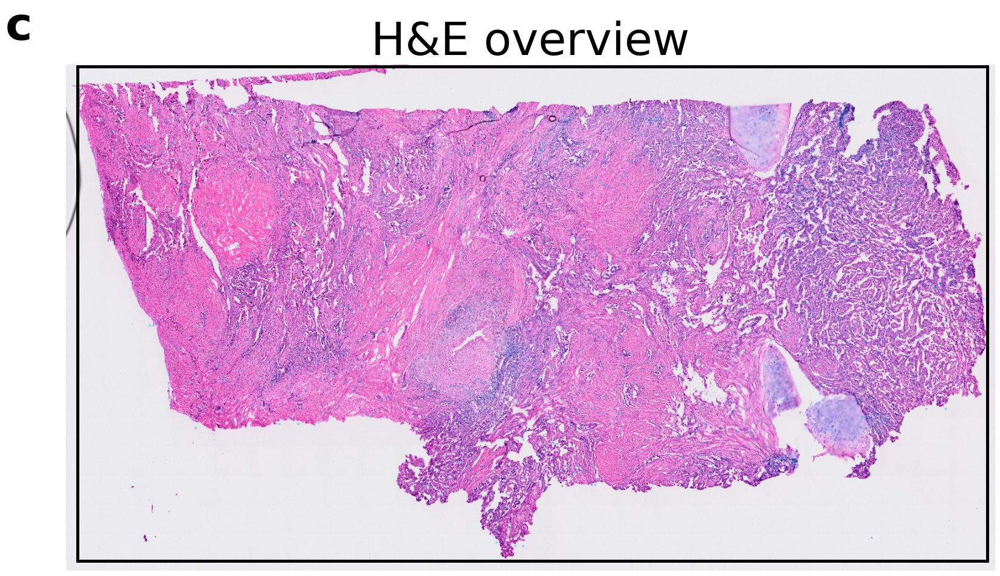

In [6]:
fig, ax = plt.subplots(figsize=(6.6, 5.5))
panel_label(ax, "c")
draw_he_footprint(ax, g32)
save_panel(fig, "c", "he_overview")

## Panel d

saved panel: ./outputs/panels/d_morphology_domains_umap.png
saved panel: ./outputs/panels/d_morphology_domains_umap.pdf


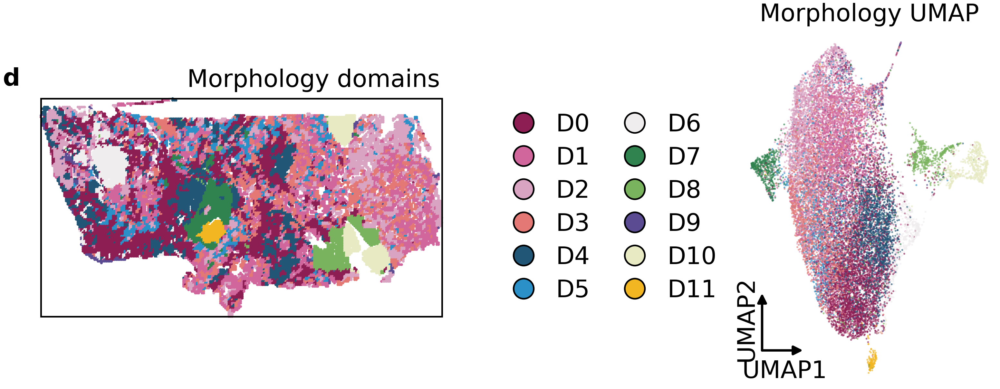

In [7]:
fig = plt.figure(figsize=(12.8, 4.8), constrained_layout=False)
gs = fig.add_gridspec(1, 2, width_ratios=[2.15, 1.0], wspace=0.38)
ax = fig.add_subplot(gs[0, 0])
panel_label(ax, "d")
categorical_spatial(ax, g32, "smoothed_domain", "Morphology domains", palette=DOMAIN_COLOR_MAP_12, legend_reserved_frac=0.36)
ax = fig.add_subplot(gs[0, 1])
categorical_umap(ax, g32, "smoothed_domain", "Morphology UMAP", legend=False, palette=DOMAIN_COLOR_MAP_12)
save_panel(fig, "d", "morphology_domains_umap")

## Panel e

saved panel: ./outputs/panels/e_representative_tiles.png
saved panel: ./outputs/panels/e_representative_tiles.pdf


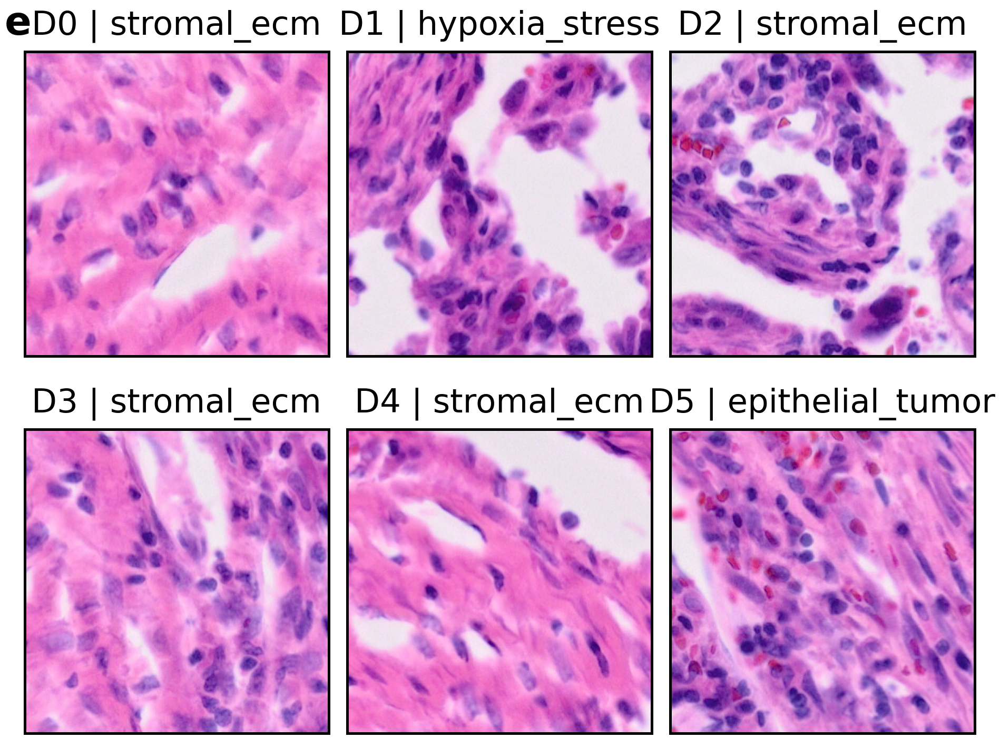

In [8]:
fig = plt.figure(figsize=(8.2, 5.6), constrained_layout=False)
gs = fig.add_gridspec(1, 1)
draw_representative_tiles(fig, gs[0, 0], representative)
save_panel(fig, "e", "representative_tiles")

## Panel f

saved panel: ./outputs/panels/f_he_cancer_enriched_region.png
saved panel: ./outputs/panels/f_he_cancer_enriched_region.pdf


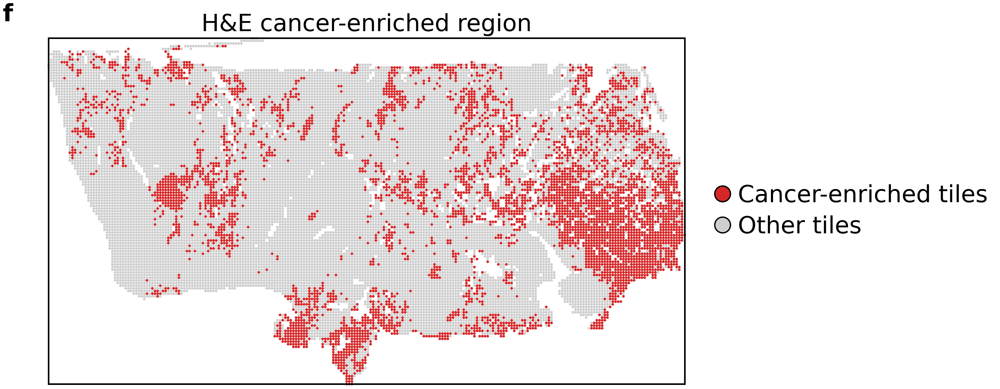

In [9]:
fig, ax = plt.subplots(figsize=(8.8, 6.6))
panel_label(ax, "f")
spatial_binary(ax, cancer, "he_cancer_region_proxy", "H&E cancer-enriched region", size=4.0)
save_panel(fig, "f", "he_cancer_enriched_region")

## Panel g

saved panel: ./outputs/panels/g_predicted_st_domains_umap.png
saved panel: ./outputs/panels/g_predicted_st_domains_umap.pdf


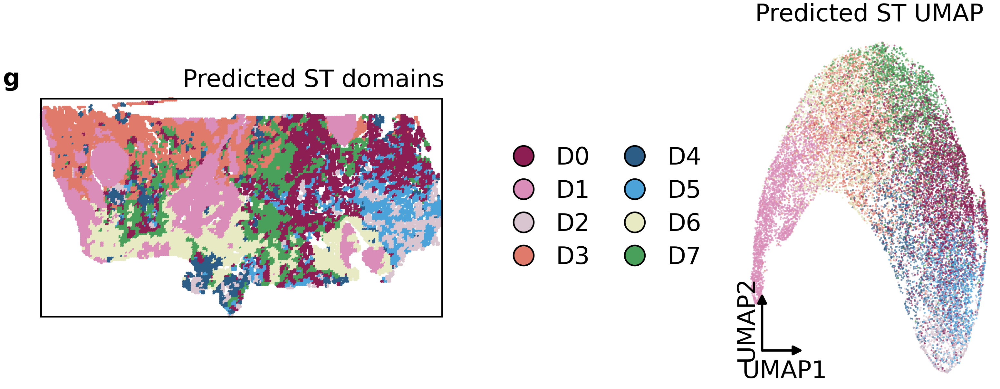

In [10]:
fig = plt.figure(figsize=(12.8, 4.8), constrained_layout=False)
gs = fig.add_gridspec(1, 2, width_ratios=[2.15, 1.0], wspace=0.38)
ax = fig.add_subplot(gs[0, 0])
panel_label(ax, "g")
categorical_spatial(ax, g32, "refined_predicted_domain", "Predicted ST domains", palette=ST_DOMAIN_PALETTE, legend_reserved_frac=0.36)
ax = fig.add_subplot(gs[0, 1])
categorical_umap(ax, g32, "refined_predicted_domain", "Predicted ST UMAP", x="st_umap1", y="st_umap2", legend=False, palette=ST_DOMAIN_PALETTE)
save_panel(fig, "g", "predicted_st_domains_umap")

## Panel h

saved panel: ./outputs/panels/h_predicted_st_marker_scores.png
saved panel: ./outputs/panels/h_predicted_st_marker_scores.pdf


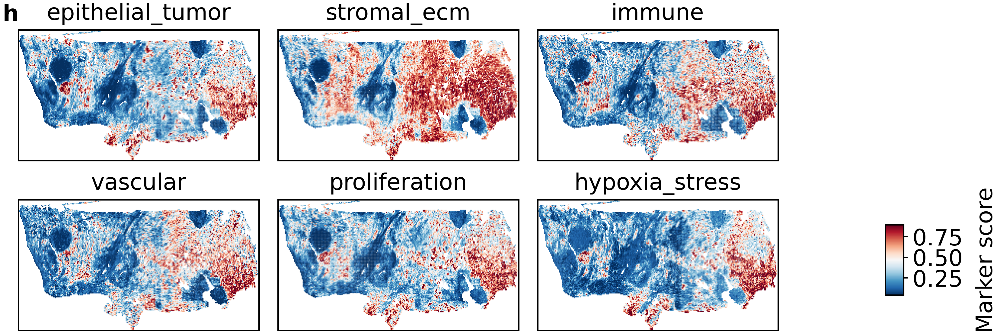

In [11]:
fig = plt.figure(figsize=(11.04, 4.32))
gs = fig.add_gridspec(2, 3, wspace=0.015, hspace=0.3)
for i, marker in enumerate(MARKER_GROUPS):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    if i == 0:
        panel_label(ax, "h")
    continuous_spatial(ax, g32, marker, marker, cmap="RdBu_r", size=1.1)
all_marker_values = g32[MARKER_GROUPS].to_numpy(dtype=float).ravel()
global_vmin = np.nanquantile(all_marker_values, 0.02)
global_vmax = np.nanquantile(all_marker_values, 0.98)
add_shared_colorbar(fig, cmap="RdBu_r", vmin=global_vmin, vmax=global_vmax, label="Marker score", fontsize=18, cax_position=(1, 0.20, 0.018, 0.18))
save_panel(fig, "h", "predicted_st_marker_scores")

## Panel i

saved panel: ./outputs/panels/i_predicted_st_tumor_immune_signatures.png
saved panel: ./outputs/panels/i_predicted_st_tumor_immune_signatures.pdf


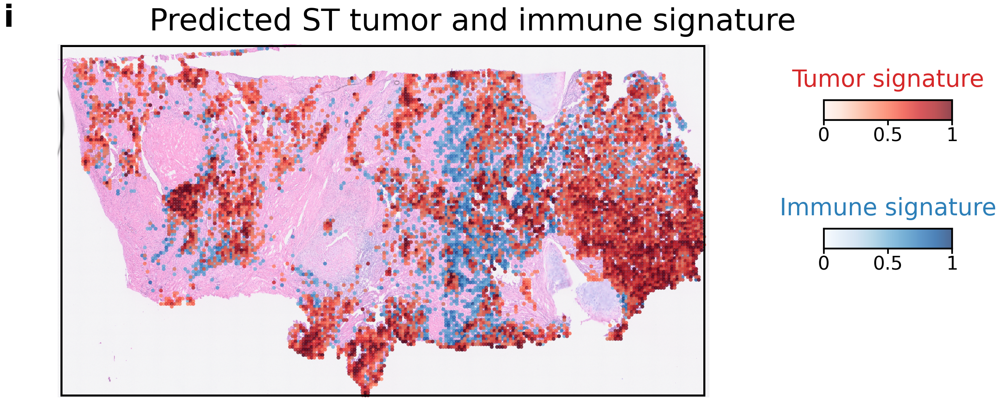

In [12]:
fig, ax = plt.subplots(figsize=(8.8, 6.6))
panel_label(ax, "i")
sc_tumor, sc_immune = spatial_tumor_immune_on_he(
    ax,
    cancer,
    title="Predicted ST tumor and immune signature",
    quantile_threshold=0.65,
    size=5.0,
    alpha=0.72,
    he_alpha=0.55,
    fontsize=18,
)
add_tumor_immune_colorbars(fig, sc_tumor, sc_immune, x0=0.84, y0=0.62, width=0.12, height=0.025, y_gap=0.16, fontsize=14)
save_panel(fig, "i", "predicted_st_tumor_immune_signatures")

## Panel j

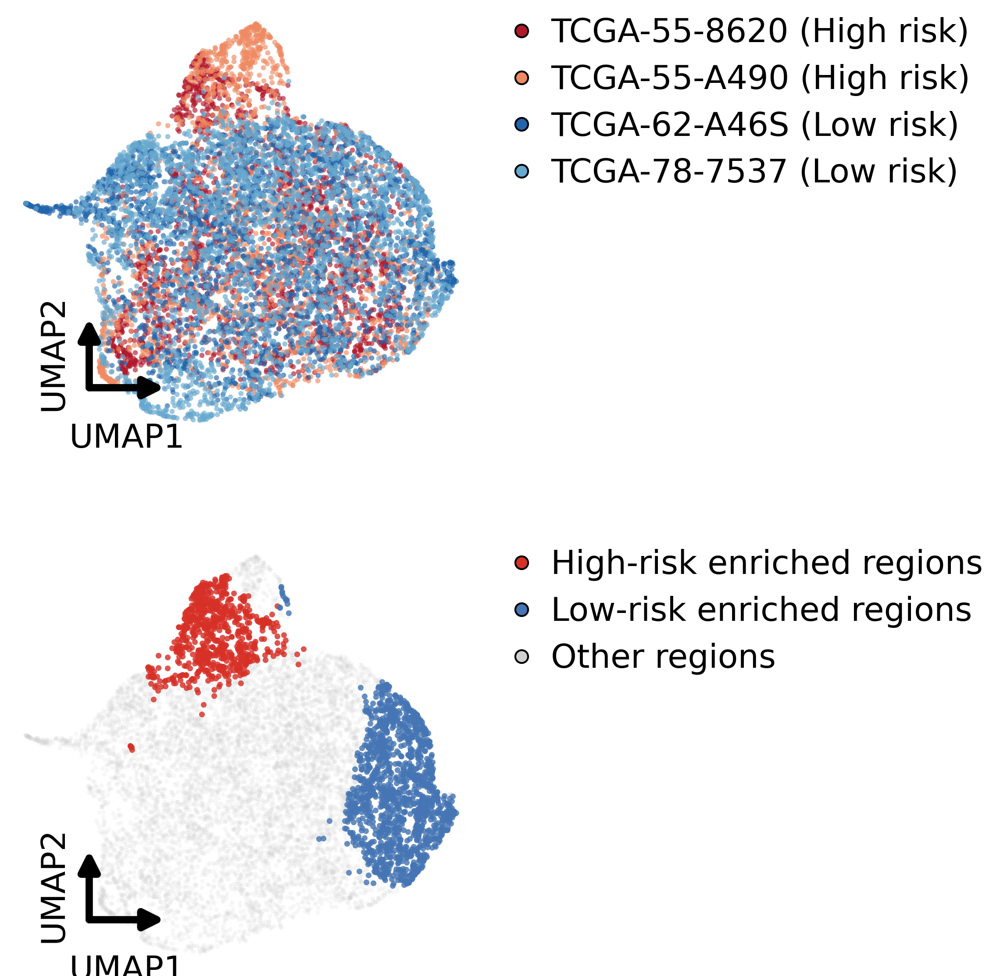

In [13]:
plot_umap_sample_vs_regions(luad, PANEL / "j_luad_matched_umap_sample_vs_key_regions")

## Panel k

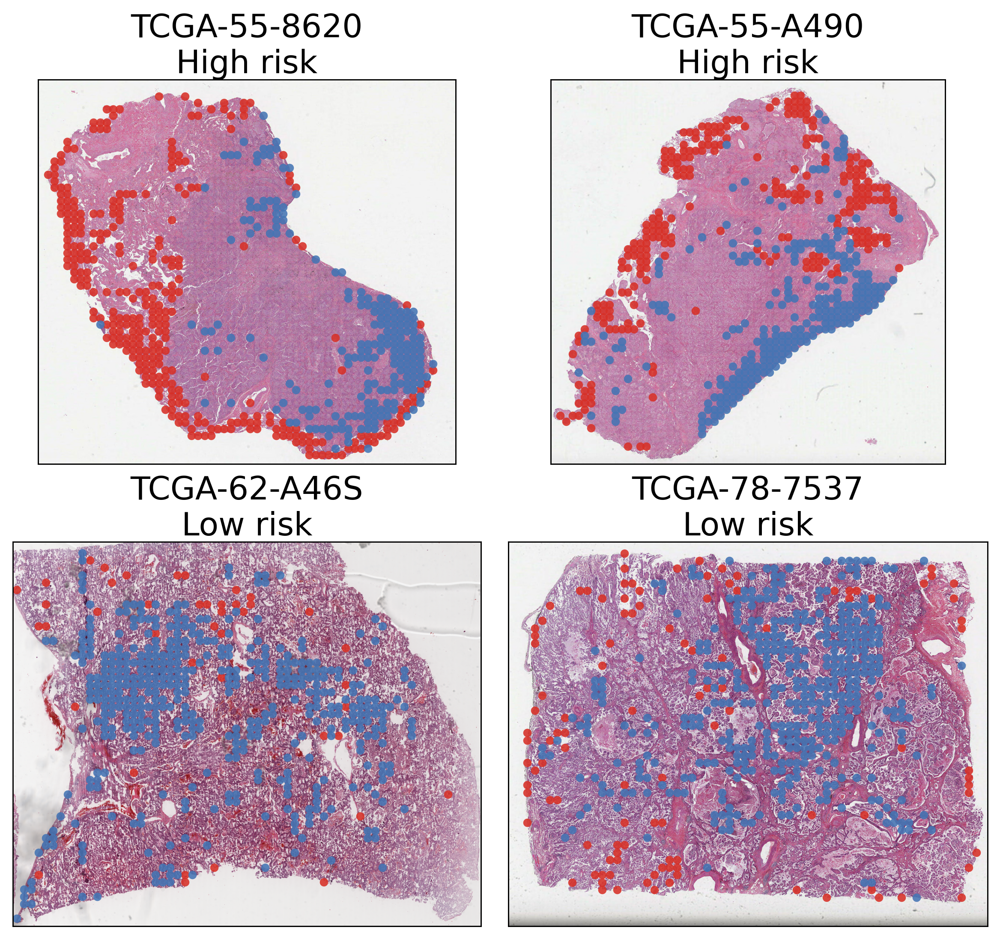

In [14]:
plot_spatial_key_regions(luad, PANEL / "k_luad_matched_spatial_key_regions")

## Panel l

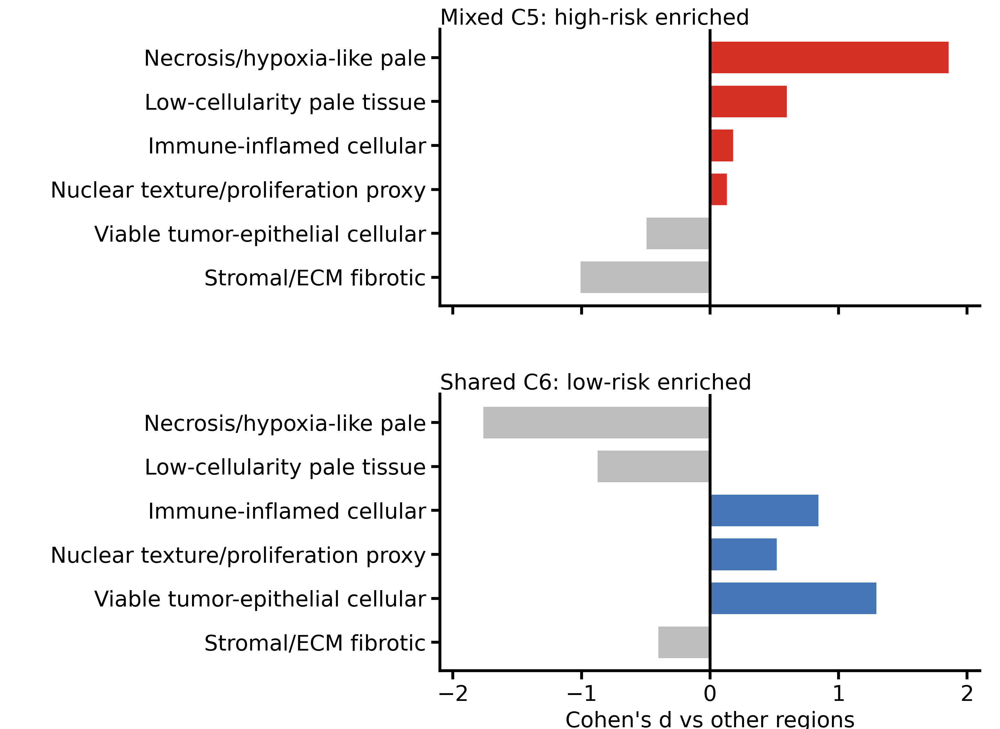

In [15]:
enrichment = plot_c5_c6_program_enrichment_stacked(luad, PANEL / "l_luad_c5_c6_program_enrichment")
enrichment.to_csv(OUT / "luad_c5_c6_program_enrichment_from_notebook.csv", index=False)

## Panel m

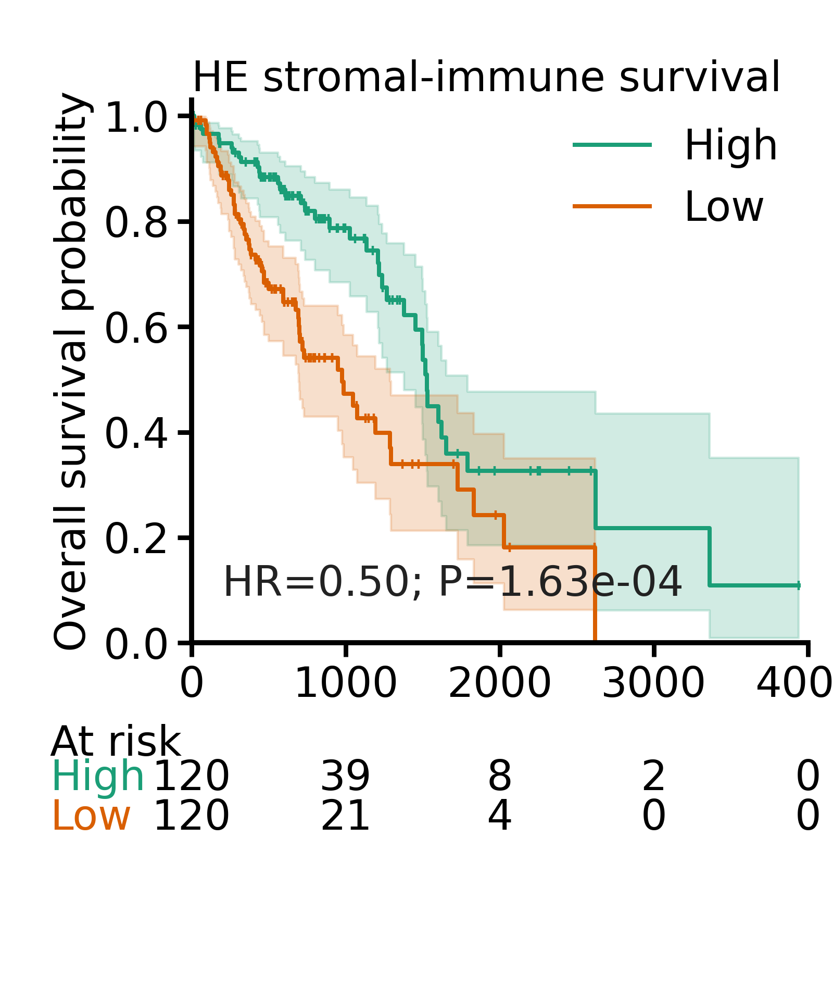

In [16]:
plot_km_styled(survival, PANEL / "m_tcga_luad_he_stromal_immune_km_styled")

## Environment

In [17]:
!pip list

Package                    Version
-------------------------- --------------
absl-py                    2.3.1
aiofiles                   25.1.0
anndata                    0.10.5.post1
annotated-types            0.7.0
anyio                      4.13.0
archspec                   0.2.3
argon2-cffi                23.1.0
argon2-cffi-bindings       21.2.0
array-api-compat           1.14.0
arrow                      1.3.0
asciitree                  0.3.3
asttokens                  2.4.1
async-lru                  2.0.4
attrs                      24.2.0
babel                      2.16.0
backrefs                   5.9
beautifulsoup4             4.12.3
bleach                     6.2.0
boltons                    24.0.0
Brotli                     1.1.0
build                      1.5.0
cached-property            1.5.2
cellrank                   2.0.7
certifi                    2026.5.20
cffi                       1.16.0
charset-normalizer         3.3.2
chex                       0.1.90
click       